<a href="https://colab.research.google.com/github/wadeea23/ECG-Based-Heartbeat-Classification-Using-Machine-Learning/blob/main/ECG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install wfdb

In [2]:
! pip install tensorflow

In [3]:
from google.colab import drive  , files
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import zipfile

zip_path = '/content/drive/MyDrive/GA/Capstone_GA/mitdb-1.0.0.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/mitdb-1.0.0')

In [5]:
import wfdb
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Conv1D, MaxPooling1D, Flatten
import joblib
import requests
from google.colab import userdata
from collections import Counter

In [6]:
folder = '/content/mitdb-1.0.0/mit-bih-arrhythmia-database-1.0.0'

print(os.listdir(folder))

['102.xws', '208.atr', '233.hea', '203.xws', '124.atr', '209.dat', '106.hea', '210.hea', '219.xws', '109.dat', 'RECORDS', '113.xws', '220.dat', '117.dat', '119.hea', '214.xws', '117.at_', '109.hea', '217.xws', '213.xws', '221.atr', '209.hea', '214.hea', '103.hea', '234.xws', '212.atr', '106.dat', '220.atr', '228.dat', '222.xws', '108.hea', '100.atr', '107.xws', '200.dat', '208.hea', '116.atr', '100.dat', '116.dat', '123.xws', '116.xws', '115.atr', '117.xws', '201.atr', '221.hea', '203.dat', '217.dat', '117.hea', '231.atr', '114.hea', '210.dat', '111.atr', '205.atr', '205.hea', '104.hea', '223.hea', '205.dat', '202.hea', '203.at_', '202.atr', '115.xws', '215.dat', '207.hea', '230.dat', '207.atr', '105.hea', '106.atr', '109.xws', '208.xws', '233.dat', '111.dat', '114.dat', '123.dat', '108.atr', '219.hea', '210.atr', '234.dat', '209.atr', '102.hea', '202.dat', '112.atr', '106.xws', '215.hea', '113.hea', '104.xws', '202.xws', '228.xws', '105.xws', '100.hea', '117.atr', '115.hea', '119.xws'

In [7]:
files = os.listdir(folder)

dat_count = str(files).count('.dat')
hea_count = str(files).count('.hea')
atr_count = str(files).count('.atr')

print("DAT:", dat_count)
print("HEA:", hea_count)
print("ATR:", atr_count)

DAT: 48
HEA: 48
ATR: 49


In [8]:
all_labels = []  # عشان اجوف كل الرموز اللي في الديتا سيت و شلون اخليهم مع بعض عقب
signals = []
for file in files:  # هاي الرموز ف ديتا سيت و صنفناهم  ع حسب المعيار العلمي

    if file.endswith('.hea'):

        name = file.replace('.hea', '')
        record = wfdb.rdrecord(folder + '/' + name)
        signal = record.p_signal[:, 0]
        signals.append(signal)
        annotation = wfdb.rdann(folder + '/' + name, 'atr')

        all_labels = all_labels + annotation.symbol

print("Signals:", len(signals))
print("Labels:", len(all_labels))
print("Label Types:", set(all_labels))


Signals: 48
Labels: 112647
Label Types: {'N', '"', '~', 'Q', 'a', ']', 'f', 'F', 'L', 'x', '[', 'j', 'J', 'S', 'V', 'A', '!', 'R', '/', '+', 'E', 'e', '|'}


In [9]:
# convert all clissy to aami in all records
N = all_labels.count('N') + all_labels.count('L') + all_labels.count('R') + all_labels.count('e') + all_labels.count('j')

S = all_labels.count('A') + all_labels.count('a') + all_labels.count('J') + all_labels.count('S')

V = all_labels.count('V') + all_labels.count('E')

F = all_labels.count('F')

Q = all_labels.count('/') + all_labels.count('f') + all_labels.count('Q')

print("N:", N)
print("S:", S)
print("V:", V)
print("F:", F)
print("Q:", Q)

N: 90631
S: 2781
V: 7236
F: 803
Q: 8043


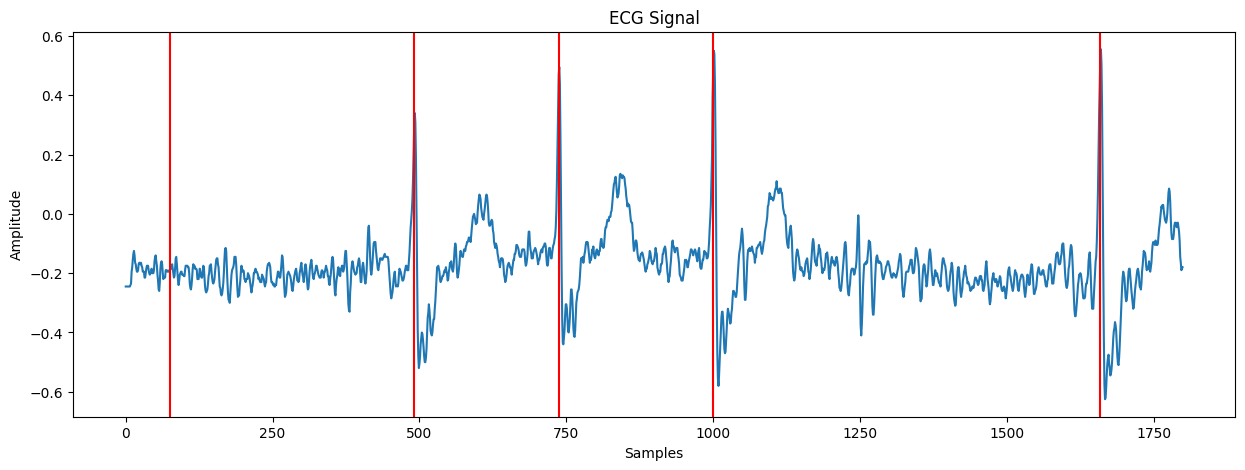

In [10]:
plt.figure(figsize=(15, 5))

plt.plot(signal[:1800]) # i choose 1800 / 360 hz = 5 sec

for peak in annotation.sample:
    if peak < 1800:
        plt.axvline(peak, color='red') # يحدد مكان النبض بالخطوط الطولية

plt.title('ECG Signal')
plt.xlabel('Samples')
plt.ylabel('Amplitude')
plt.show()

In [11]:
# Heartbeat to prepare the data to train models

In [12]:
# i will prapare the data to 48 record

In [13]:
X = []
y = []

for file in files:

    if file.endswith('.hea'):

        name = file.replace('.hea', '')

        record = wfdb.rdrecord(folder + '/' + name)
        annotation = wfdb.rdann(folder + '/' + name, 'atr')

        signal = record.p_signal[:, 0]

        for i in range(len(annotation.sample)):

            peak = annotation.sample[i]
            label = annotation.symbol[i]

            if label in ['N', 'L', 'R', 'e', 'j']:
                label = 'N'

            elif label in ['A', 'a', 'J', 'S']:
                label = 'S'

            elif label in ['V', 'E']:
                label = 'V'

            elif label != 'F':
                continue

            if peak >= 120 and peak + 240 <= len(signal):

                beat = signal[peak-120:peak+240]

                X.append(beat)
                y.append(label)

X = np.array(X)
y = np.array(y)

X = (X - X.mean(axis=1, keepdims=True)) / (X.std(axis=1, keepdims=True) + 0.00000001)

print("X Shape:", X.shape)
print("Y Shape:", y.shape)

X Shape: (101396, 360)
Y Shape: (101396,)


In [14]:
# model 1 split the data

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42,stratify=y_train)

In [16]:
# model 1 binary label 0=normal / 1=abnormal

In [17]:
y_train_binary = (y_train != 'N').astype(int) # to convert n to 0 other to 1
y_val_binary = (y_val != 'N').astype(int)
y_test_binary = (y_test != 'N').astype(int)

In [18]:
## dt for bainary model

In [19]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train_binary)

pred = dt_model.predict(X_val)

print(classification_report(y_val_binary, pred))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98      9058
           1       0.87      0.85      0.86      1082

    accuracy                           0.97     10140
   macro avg       0.92      0.92      0.92     10140
weighted avg       0.97      0.97      0.97     10140



In [20]:
pred = dt_model.predict(X_test)

print(classification_report(y_test_binary, pred))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98     18117
           1       0.86      0.86      0.86      2163

    accuracy                           0.97     20280
   macro avg       0.92      0.92      0.92     20280
weighted avg       0.97      0.97      0.97     20280



In [21]:
# knn model

In [22]:
scaler = StandardScaler()   # preprocessing
X_train_scaler = scaler.fit_transform(X_train)
X_val_scaler = scaler.transform(X_val)
X_test_scaler = scaler.transform(X_test)

In [23]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaler, y_train_binary)

knn_pred = knn_model.predict(X_val_scaler)

print(classification_report(y_val_binary, knn_pred))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      9058
           1       0.96      0.90      0.93      1082

    accuracy                           0.99     10140
   macro avg       0.97      0.95      0.96     10140
weighted avg       0.99      0.99      0.99     10140



In [24]:
pred = knn_model.predict(X_test_scaler)

print(classification_report(y_test_binary, pred))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99     18117
           1       0.96      0.91      0.94      2163

    accuracy                           0.99     20280
   macro avg       0.98      0.95      0.97     20280
weighted avg       0.99      0.99      0.99     20280



In [25]:
# cnn model

In [26]:
encoder = LabelEncoder()
encoder.fit(y_train[y_train != 'N'])
y_train_encoded = np.zeros(len(y_train), dtype=int)
y_val_encoded = np.zeros(len(y_val), dtype=int)
y_test_encoded = np.zeros(len(y_test), dtype=int)
y_train_encoded[y_train != 'N'] = encoder.transform(y_train[y_train != 'N'])
y_val_encoded[y_val != 'N'] = encoder.transform(y_val[y_val != 'N'])
y_test_encoded[y_test != 'N'] = encoder.transform(y_test[y_test != 'N'])


In [27]:
# for imbalanced data
binary_weight = compute_class_weight(class_weight='balanced', classes=np.unique(y_train_binary), y=y_train_binary)
type_weight = compute_class_weight(class_weight='balanced', classes=np.unique(y_train_encoded[y_train != 'N']), y=y_train_encoded[y_train != 'N'])
print(binary_weight)
print(type_weight)

[0.55971232 4.68674062]
[4.4911032  1.29701953 0.49842022]


In [28]:
X_train_cnn = X_train.reshape(-1, 360, 1)
X_val_cnn = X_val.reshape(-1, 360, 1)
X_test_cnn = X_test.reshape(-1, 360, 1)


In [29]:
binary_sample_weight = binary_weight[y_train_binary]
type_sample_weight = np.zeros(len(y_train))
type_sample_weight[y_train != 'N'] = type_weight[y_train_encoded[y_train != 'N']]

binary_val_weight = np.ones(len(y_val))
type_val_weight = (y_val != 'N').astype(float)

In [30]:
input_layer = Input(shape=(360, 1))

x = Conv1D(32, 3, activation='relu')(input_layer)
x = MaxPooling1D(2)(x)
x = Conv1D(64, 3, activation='relu')(x)
x = MaxPooling1D(2)(x)
x = Flatten()(x)
x = Dense(64, activation='relu')(x)

binary_output = Dense(1, activation='sigmoid', name='binary_output')(x)
type_output = Dense(3, activation='softmax', name='type_output')(x)

cnn_model = Model(inputs=input_layer, outputs=[binary_output, type_output])

In [31]:
cnn_model.compile(optimizer='adam',loss=['binary_crossentropy', 'sparse_categorical_crossentropy'],weighted_metrics=[['accuracy'], ['accuracy']])

In [32]:
history = cnn_model.fit(X_train_cnn, [y_train_binary, y_train_encoded], epochs=10, batch_size=32, validation_data=(X_val_cnn, [y_val_binary, y_val_encoded]),sample_weight=[binary_sample_weight, type_sample_weight])

Epoch 1/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 55s 24ms/step - binary_output_accuracy: 0.9304 - binary_output_loss: 0.1803 - loss: 0.2066 - type_output_accuracy: 0.9146 - type_output_loss: 0.0264 - val_binary_output_accuracy: 0.9742 - val_binary_output_loss: 0.0851 - val_loss: 2.2433 - val_type_output_accuracy: 0.5244 - val_type_output_loss: 2.1580
Epoch 2/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 50s 23ms/step - binary_output_accuracy: 0.9661 - binary_output_loss: 0.0970 - loss: 0.1121 - type_output_accuracy: 0.9460 - type_output_loss: 0.0151 - val_binary_output_accuracy: 0.9759 - val_binary_output_loss: 0.0809 - val_loss: 2.0435 - val_type_output_accuracy: 0.4654 - val_type_output_loss: 1.9625
Epoch 3/10
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 52s 23ms/step - binary_output_accuracy: 0.9759 - binary_output_loss: 0.0719 - loss: 0.0837 - type_output_accuracy: 0.9594 - type_output_loss: 0.0118 - val_binary_output_accuracy: 0.9792 - val_binary_output_loss: 0.0905 - val_loss: 2.5894 - val_type_output_accuracy: 

In [33]:
pred = cnn_model.predict(X_val_cnn)
pred = (pred[0] > 0.5).astype(int)
print(classification_report(y_val_binary, pred))

317/317 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      9058
           1       0.92      0.95      0.94      1082

    accuracy                           0.99     10140
   macro avg       0.96      0.97      0.97     10140
weighted avg       0.99      0.99      0.99     10140



In [34]:
pred = cnn_model.predict(X_test_cnn)

binary_predictions = (pred[0].flatten() > 0.5).astype(int)

print(classification_report(y_test_binary, binary_predictions))

634/634 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step
              precision    recall  f1-score   support

           0       0.99      0.99      0.99     18117
           1       0.93      0.95      0.94      2163

    accuracy                           0.99     20280
   macro avg       0.96      0.97      0.97     20280
weighted avg       0.99      0.99      0.99     20280



In [35]:
normal_count = int(np.sum(binary_predictions == 0))
abnormal_count = int(np.sum(binary_predictions == 1))

abnormal_types = encoder.inverse_transform(
    np.argmax(pred[1][binary_predictions == 1], axis=1))

type_counts = Counter(abnormal_types)


In [36]:
print("Normal:", normal_count)
print("Abnormal:", abnormal_count)
print("Types:", type_counts)


Normal: 18059
Abnormal: 2221
Types: Counter({np.str_('V'): 1416, np.str_('S'): 591, np.str_('F'): 214})


In [49]:

def make_report(result, normal, abnormal, types):

    if result == "NORMAL":
        prompt = """
        Write a simple English ECG report.

        Overall Result: NORMAL

        Explain that the detected heartbeats were classified as normal.

        Important Note:
        This is an experimental machine learning project,
        not a medical device. It cannot diagnose diseases.

        Do not mention abnormal beats or their definitions.
        Do not mention PVC, Fusion Beat, or Supraventricular Beat.
        Do not include Detected Beat Types.
        Do not show beat counts, BPM, or Recovery Time.
        """

    else:
        prompt = f"""
        Write a simple English ECG report.

        Overall Result: ABNORMAL

        Detected Beat Types: {dict(types)}

        Explain only the detected beat types.
        Do not mention other types.

        Recommend consulting a doctor.

        Important Note:
        This is an experimental machine learning project,
        not a medical device. It cannot diagnose diseases.

        Do not show beat counts, BPM, or Recovery Time.
        """

    r = requests.post(
        "https://openrouter.ai/api/v1/chat/completions",
        headers={
            "Authorization": f"Bearer {st.secrets['OPENROUTER_API_KEY']}",
            "Content-Type": "application/json"
        },
        json={
            "model": "openrouter/auto",
            "messages": [{"role": "user", "content": prompt}],
            "temperature": 0.3
        },
        timeout=60
    )

    r.raise_for_status()
    report = r.json()["choices"][0]["message"]["content"]

    pdf = io.BytesIO()
    styles = getSampleStyleSheet()
    content = [Paragraph("ECG Report", styles["Title"]), Spacer(1, 15)]

    for line in report.splitlines():
        if line.strip():
            content.append(Paragraph(escape(line), styles["Normal"]))
            content.append(Spacer(1, 7))

    SimpleDocTemplate(pdf).build(content)

    st.session_state.report = report
    st.session_state.pdf = pdf.getvalue()


In [47]:
report = generate_report(normal_count, abnormal_count, type_counts)

print(report)


1. Overall Result:
Abnormal

2. Detected Beat Types:
- Premature Ventricular Contraction: An early heartbeat that starts in the lower chambers of the heart (ventricles).
- Fusion of Ventricular and Normal Beat: A heartbeat that combines normal and ventricular electrical signals.
- Supraventricular Premature Beat: An early heartbeat that starts above the ventricles.

These detected types are abnormal beat patterns.

3. What Does This Mean?
The recording shows different abnormal heartbeat patterns. Premature ventricular contractions are early beats from the lower chambers. Supraventricular premature beats are early beats from above the ventricles. Fusion beats are mixed beats that combine normal and ventricular electrical signals. Because the final result is Abnormal, it is recommended to consult a doctor for proper review.

4. Important Note:
This is an experimental machine learning project, not a medical device. It cannot diagnose diseases. A Normal result does not guarantee perfect he

In [48]:
cnn_model.save('best_model2.keras')

In [41]:
files.download('best_model2.keras')

AttributeError: 'list' object has no attribute 'download'

In [ ]:
joblib.dump(encoder, 'encoder.pkl')

files.download('encoder.pkl')